# Unsupervised Machine Learning – K-Means Clustering
**End-to-End Executable Practical Notebook**

K-Means partitions unlabeled data into $K$ distinct clusters by minimizing **Within-Cluster Sum of Squares (WCSS)** using Euclidean distance.

### Step 1: Import Libraries

In [1]:
print(1)

1


In [4]:
%pip install matplotlib

^C
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.3 MB 2.1 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/9.3 MB 2.5 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.3 MB 2.9 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.3 MB 3.0 MB/s eta 0:00:02
   -------------------- ------------------- 4.7/9.3 MB 3.2 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.3 MB 3.3 MB/s eta 0:00:02
   ---------------------------- ----------- 6.6/9.3 MB 3.5 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 3.6 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.3 MB 3.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/

In [7]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

### Step 2: Load Customer Dataset
- (`Age`, `Annual_Income`, `Spending_Score`, `Purchases`, `Website_Visits`)

In [9]:
df = pd.read_csv(r"D:\DATA SCIENCE\ds\kmeans_clusters.csv")

In [10]:
df

,Age,Annual_Income,Spending_Score,Purchases,Website_Visits,Cluster
0,26.864599,168118.389823,96.613835,26.703981,0.000000,2
1,18.000000,15000.000000,100.000000,29.755009,30.165095,0
2,29.033293,150930.032140,99.594994,29.208672,0.000000,2
3,25.623295,138918.741460,90.094828,20.791111,0.000000,2
4,18.000000,158837.990833,100.000000,0.000000,0.000000,1
...,...,...,...,...,...,...
19995,18.000000,189145.145709,100.000000,0.000000,0.000000,1
19996,18.000000,15000.000000,100.000000,37.334994,25.664562,0
19997,18.581090,146351.412456,100.000000,35.841113,0.000000,2
19998,18.000000,155210.157505,100.000000,0.000000,0.000000,1


### Step 3 & 4: Missing Value Imputation & Feature Scaling
Because K-Means relies on Euclidean distance, features on larger scales (like `Annual_Income`) will dominate distance calculations unless standardized.

In [11]:
# Check and impute missing values
print("Missing values:", df.isnull().sum())

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df)

# Standardize features (Mean = 0, Std = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=df.columns
)

display(X_scaled.head())

Missing values: Age               0
Annual_Income     0
Spending_Score    0
Purchases         0
Website_Visits    0
Cluster           0
dtype: int64


,Age,Annual_Income,Spending_Score,Purchases,Website_Visits,Cluster
0,1.135733,1.223581,0.498422,0.590761,-0.601934,0.461056
1,-0.475468,-1.053361,0.662714,0.809137,1.574616,-1.327542
2,1.529908,0.967982,0.643063,0.770033,-0.601934,0.461056
3,0.910117,0.789369,0.182129,0.167551,-0.601934,0.461056
4,-0.475468,1.085577,0.662714,-1.320561,-0.601934,-0.433243


### Step 5: Evaluate Optimal K (K = 2 to 10)
Compute **WCSS (Inertia)**, **Silhouette Score** (higher is better), **Davies-Bouldin Index** (lower is better), and **Calinski-Harabasz Score** (higher is better).

In [12]:
k_values = range(2, 11)

wcss = []
silhouette_scores = []
db_scores = []
ch_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    cluster_labels = model.fit_predict(X_scaled)

    wcss.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, cluster_labels))
    db_scores.append(davies_bouldin_score(X_scaled, cluster_labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, cluster_labels))

results = pd.DataFrame({
    "K": list(k_values),
    "WCSS": wcss,
    "Silhouette_Score": silhouette_scores,
    "Davies_Bouldin": db_scores,
    "Calinski_Harabasz": ch_scores
})

display(results.round(4))

,K,WCSS,Silhouette_Score,Davies_Bouldin,Calinski_Harabasz
0,2,73409.6978,0.4535,0.7752,12691.9589
1,3,39749.0786,0.5741,0.7561,20186.3506
2,4,17768.4155,0.6754,0.5574,38349.3727
3,5,13128.5298,0.6509,0.6825,40691.9165
4,6,11527.7689,0.5693,0.8838,37627.3399
5,7,10191.8881,0.5505,0.9591,35901.0802
6,8,9289.9938,0.4435,1.0822,34035.3957
7,9,8721.3035,0.4342,1.0923,31884.5396
8,10,8223.0682,0.4185,1.1820,30192.1828


### Steps 6 – 9: Visualize Cluster Evaluation Metrics

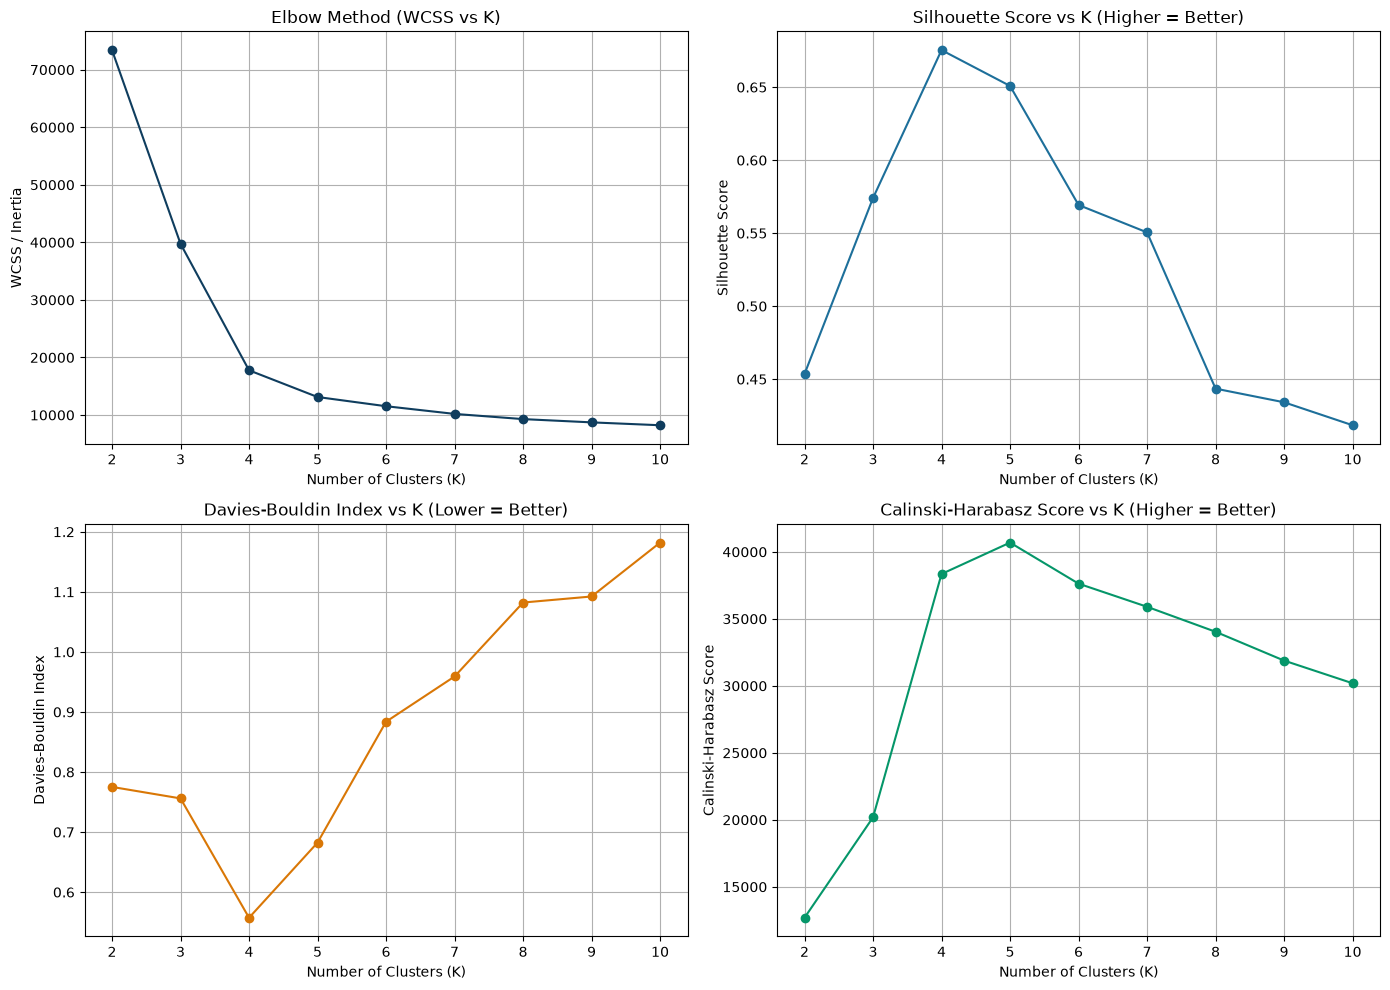

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow Graph
axes[0, 0].plot(list(k_values), wcss, marker="o", color="#0F3D5E")
axes[0, 0].set_title("Elbow Method (WCSS vs K)")
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("WCSS / Inertia")
axes[0, 0].set_xticks(list(k_values))
axes[0, 0].grid(True)

# Silhouette Score Graph
axes[0, 1].plot(list(k_values), silhouette_scores, marker="o", color="#1D6F9A")
axes[0, 1].set_title("Silhouette Score vs K (Higher = Better)")
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("Silhouette Score")
axes[0, 1].set_xticks(list(k_values))
axes[0, 1].grid(True)

# Davies-Bouldin Graph
axes[1, 0].plot(list(k_values), db_scores, marker="o", color="#D97706")
axes[1, 0].set_title("Davies-Bouldin Index vs K (Lower = Better)")
axes[1, 0].set_xlabel("Number of Clusters (K)")
axes[1, 0].set_ylabel("Davies-Bouldin Index")
axes[1, 0].set_xticks(list(k_values))
axes[1, 0].grid(True)

# Calinski-Harabasz Graph
axes[1, 1].plot(list(k_values), ch_scores, marker="o", color="#059669")
axes[1, 1].set_title("Calinski-Harabasz Score vs K (Higher = Better)")
axes[1, 1].set_xlabel("Number of Clusters (K)")
axes[1, 1].set_ylabel("Calinski-Harabasz Score")
axes[1, 1].set_xticks(list(k_values))
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

### Steps 10 – 13: Train Final Model, Check Distribution & Profile Clusters
Train the model with `optimal_k = 4` and examine mean feature values per cluster to assign business interpretations.

Cluster Counts: Cluster
3    5311
0    5004
1    5002
2    4683
Name: count, dtype: int64


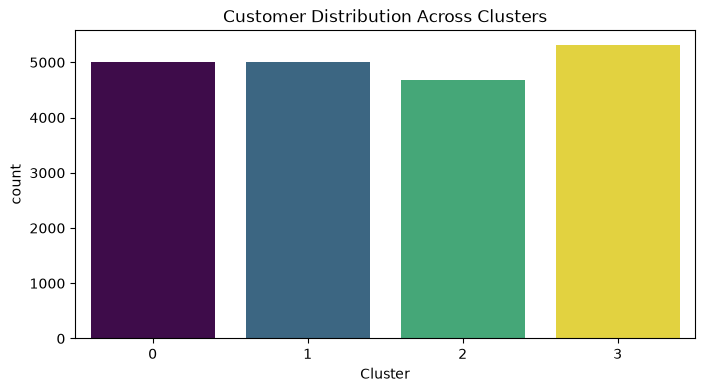

,Age,Annual_Income,Spending_Score,Purchases,Website_Visits
Cluster,,,,,
0,18.36,24992.13,54.68,13.43,1.62
1,18.15,15018.75,99.62,30.03,31.58
2,28.57,149717.54,91.94,30.49,0.04
3,18.05,153531.16,98.74,1.65,0.11


In [14]:
optimal_k = 4  #10,5,6

kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# Check Cluster Distribution
print("Cluster Counts:", df["Cluster"].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Cluster", palette="viridis", hue="Cluster", legend=False)
plt.title("Customer Distribution Across Clusters")
plt.show()

# Cluster Profiling
cluster_profile = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual_Income": "mean",
    "Spending_Score": "mean",
    "Purchases": "mean",
    "Website_Visits": "mean"
}).round(2)

display(cluster_profile)

### Segmented Customer Clusters Table :-

|   Cluster_ID | Cluster_Name               |   Age |   Annual_Income ($) |   Spending_Score |   Purchases |   Website_Visits | Derived_Insights                                                                           |
|-------------:|:---------------------------|------:|--------------------:|-----------------:|------------:|-----------------:|:-------------------------------------------------------------------------------------------|
|            0 | Active Digital Enthusiasts | 18.15 |             15018.8 |            99.62 |       30.03 |            31.58 | High online engagement & frequent small/discounted purchases despite low income.           |
|            1 | Affluent Youth Prodigies   | 18.05 |            153531   |            98.74 |        1.65 |             0.11 | High-ticket luxury/impulse buyers; minimal web visits, very few but high-value orders.     |
|            2 | Affluent Careerists        | 28.57 |            149718   |            91.94 |       30.49 |             0.04 | Loyal, high-earning repeat buyers purchasing directly (in-store/app) without web browsing. |
|            3 | Casual Budget Shoppers     | 18.36 |             24992.1 |            54.68 |       13.43 |             1.62 | Price-sensitive baseline customers with moderate spending and steady, average engagement.  |

### Steps 14 – 16: Visualize Clusters, Inverse-Transform Centroids & Predict New Customer
*Note: Always use the **already fitted** `imputer` and `scaler` when transforming new data.*

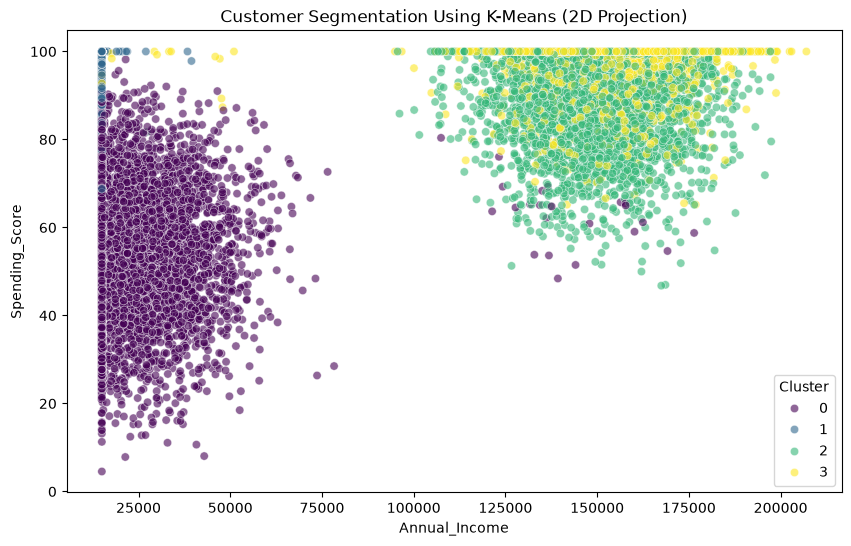

ValueError: Shape of passed values is (4, 6), indices imply (4, 5)

In [16]:
# 2D Scatter Projection
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="viridis",
    alpha=0.6
)
plt.title("Customer Segmentation Using K-Means (2D Projection)")
plt.show()

# Inverse-Transform Centroids back to Original Scale
centroids_scaled = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=["Age", "Annual_Income", "Spending_Score", "Purchases", "Website_Visits"]
).round(2)
print("Cluster Centroids (Original Scale):")
display(centroid_df)

# Predict Cluster for a New Customer
new_customer = pd.DataFrame({
    "Age": [30],
    "Annual_Income": [70000],
    "Spending_Score": [85],
    "Purchases": [40],
    "Website_Visits": [25]
})

new_customer_scaled = scaler.transform(new_customer)
predicted_cluster = kmeans.predict(new_customer_scaled)
print("Predicted Cluster for New Customer:", predicted_cluster[0])

In [19]:
print(df.columns)

Index(['Age', 'Annual_Income', 'Spending_Score', 'Purchases', 'Website_Visits',
       'Cluster'],
      dtype='str')


In [17]:
print(centroids_original.shape)

(4, 6)


### Bonus: PCA Dimensionality Reduction & Train-Test Generalization Check
1. **PCA**: Projects 5D scaled features into 2 principal components for visualization.
2. **Train-Test Split**: Evaluates whether cluster assignments remain consistent on unseen data.

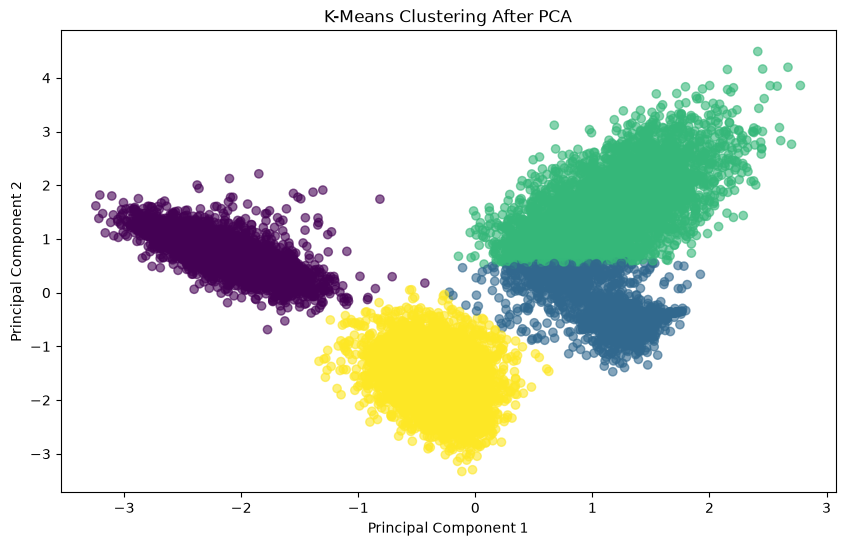

Train Silhouette Score: 0.6414
Test Silhouette Score : 0.6468


In [ ]:
# 1. K-Means with PCA (2 Components)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

kmeans_pca = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_pca = kmeans_pca.fit_predict(X_pca)

plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_pca, cmap="viridis", alpha=0.6)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering After PCA")
plt.show()

# 2. Train-Test Split Generalization Check
X_train, X_test = train_test_split(X_scaled, test_size=0.2, random_state=42)

kmeans_val = KMeans(n_clusters=4, n_init=10, random_state=42)
kmeans_val.fit(X_train)

train_labels = kmeans_val.predict(X_train)
test_labels = kmeans_val.predict(X_test)

print("Train Silhouette Score:", round(silhouette_score(X_train, train_labels), 4))
print("Test Silhouette Score :", round(silhouette_score(X_test, test_labels), 4))